In [2]:
##################################################################################################################
####### CODE FOR FITTING THE XGB MODEL - TRAINED ON ALL DATA BUT WITH HYPERPARAMETERS FROM TRAINING DATASET ######
##################################################################################################################

### Sarah Berk sberk@unc.edu 10 March 2025 ###

##################### MANUAL ###########################

# Environment: durham_ml_venv
# Kernel: durham_ml_kernel

#Read in the packages to use
import numpy as np
import pandas as pd
import math
import datetime
import os
import pathlib
import matplotlib.pyplot as plt
import pandas as pd
import pickle
from xgboost import XGBRegressor
import joblib
from sklearn.preprocessing import StandardScaler 

import pvlib
import pytz

# load in the data to fit the model 
data = pd.read_csv("ERA5_everyday_merged.csv")

# data for testing models trained on only one landcover type or shading scenario
sensor_info = pd.read_csv('Data/Installed Sensors_0.csv')
sensor_info = sensor_info.rename(columns = {'Sensor Serial Number':'Sensor_ID'})
vegetation_only_IDs = sensor_info[sensor_info['Landcover Type'] == 'vegetation'].Sensor_ID.values
impervious_only_IDs = sensor_info[sensor_info['Landcover Type'] == 'impervious'].Sensor_ID.values
shaded_only_IDs = sensor_info[sensor_info['Shade Type'] == 'shaded'].Sensor_ID.values
unshaded_only_IDs = sensor_info[sensor_info['Shade Type'] == 'non-shaded'].Sensor_ID.values

#### ----- Uncomment the relevent filtering below if you want to test one of these ------- 

#landcover_shade_bias_test = 'None'
#landcover_shade_bias_test = 'vegetation_only'
#landcover_shade_bias_test = 'impervious_only'
#landcover_shade_bias_test = 'shaded_only'
#landcover_shade_bias_test = 'unshaded_only'
landcover_shade_bias_test = 'afternoon_only'

if landcover_shade_bias_test == 'None':
    pass
elif landcover_shade_bias_test == 'vegetation_only':
    data = data[data.Sensor_ID.isin(vegetation_only_IDs)]
elif landcover_shade_bias_test == 'impervious_only':
    data = data[data.Sensor_ID.isin(impervious_only_IDs)]
elif landcover_shade_bias_test == 'shaded_only':
    data = data[data.Sensor_ID.isin(shaded_only_IDs)]
elif landcover_shade_bias_test == 'unshaded_only':
    data = data[data.Sensor_ID.isin(unshaded_only_IDs)]
elif landcover_shade_bias_test == 'afternoon_only':
    test_hours = [1, 12, 13]
    data = data[data.Hour.isin(test_hours)]

#
# get the zenith angle 
# convert to UTC for use in pvlib 
data['edt_datetime'] = pd.to_datetime(data['edt_datetime']).dt.tz_localize('US/Eastern')
data['utc_datetime'] = data['edt_datetime'].dt.tz_convert('UTC')

durham_lat = 35.99260
durham_lon = -78.89892
# calc solar positions
solpos = pvlib.solarposition.get_solarposition(
    time=data['utc_datetime'],
    latitude=durham_lat,
    longitude=durham_lon
)

# Add zenith angle to data 
data['zenith_angle'] = solpos['zenith'].values

# add in a temp anom quantification to use as target variable
data['temp_anom'] = data['Temperature'] - data['temperature_2m'] 
# add in rh anom quantification to use as target variable
data['rh_anom'] = data['Relative_Humidity'] - data['relative_humidity_2m'] 

### --- Define Model specs -----
# define Y and X
Y_name = "temp_anom"

# static variables first, then dynamic
X_names_day =[ 'NDBI_2024SummerMosaic', 'NDVI_2024SummerMosaic', 'ESA_50',  
         'nearest_motorway_thru_primary_dist','NDMI', 'Tree_DSM_SVF','Albedo_2024SummerMosaic',
         'zenith_angle', 'surface_net_thermal_radiation_hourly','surface_solar_radiation_downwards_hourly',
        'surface_thermal_radiation_downwards_hourly',  'surface_solar_radiation_downwards_accumulation',
        'u_component_of_wind_10m',  'v_component_of_wind_10m', 'windspeed_10m', 
        'relative_humidity_2m', 'temperature_2m', 'total_precipitation_hourly',
           ]

X_names_night =[ 'NDBI_2024SummerMosaic', 'NDVI_2024SummerMosaic', 'ESA_50',  
         'nearest_motorway_thru_primary_dist', 'Tree_DSM_SVF',
         'zenith_angle', 'surface_net_thermal_radiation_hourly',
        'surface_thermal_radiation_downwards_hourly',  'surface_solar_radiation_downwards_accumulation',
        'u_component_of_wind_10m',  'v_component_of_wind_10m', 'windspeed_10m', 
        'relative_humidity_2m', 'temperature_2m', 'total_precipitation_hourly',
           ]

# modelling for no incoming sol rad (nighttime)
data_no_sol_rad = data[data['surface_solar_radiation_downwards_hourly'] < 1].copy().reset_index(drop = True)
y_night = data_no_sol_rad[Y_name].copy()
X_night = data_no_sol_rad[X_names_night].copy()

#create normalised datasets and save the scalers
scaler = StandardScaler()
X_night_norm = pd.DataFrame(scaler.fit_transform(X_night.values), columns = X_night.columns) #fit and transform
if landcover_shade_bias_test =='None':
    filename = 'night_scaler.sav'
else: filename = f'night_scaler_{landcover_shade_bias_test}.sav'
joblib.dump(scaler, filename, compress = 0)

# modelling for incoming sol rad (daytime)
data_sol_rad = data[data['surface_solar_radiation_downwards_hourly'] > 1].copy().reset_index(drop = True)
y_day = data_sol_rad[Y_name].copy()
X_day = data_sol_rad[X_names_day].copy()

#create normalised datasets
scaler = StandardScaler()
X_day_norm = pd.DataFrame(scaler.fit_transform(X_day.values), columns = X_day.columns) #fit and transform
if landcover_shade_bias_test =='None':
    filename = 'day_scaler.sav'
else: filename = f'day_scaler_{landcover_shade_bias_test}.sav'
joblib.dump(scaler, filename, compress = 0)


['day_scaler_afternoon_only.sav']

In [52]:
import sys
print(sys.executable)

/nas/longleaf/home/sberk/.conda/envs/durham_ml_venv/bin/python3.13


In [3]:
# fit and save the models 

# Daytime Model
day_xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42,
                             n_estimators =883,max_depth = 8, learning_rate = 0.059,
                             subsample = 0.6,colsample_bytree = 0.61, min_child_weight =17,
                             gamma =  0.001,reg_alpha =0.0001 ,reg_lambda=80) 

day_xgb_model.fit(X_day_norm, y_day)

#save the file using joblib
if landcover_shade_bias_test =='None':
    filename = 'xgb_model_daytime.sav'
else: filename = f'xgb_model_daytime_{landcover_shade_bias_test}.sav'
joblib.dump(day_xgb_model, filename)



['xgb_model_daytime_afternoon_only.sav']

In [4]:
# Nighttime Model
night_xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42,
                             n_estimators =700,max_depth = 7, learning_rate = 0.2,
                             subsample = 0.9,colsample_bytree = 0.4, min_child_weight =26,
                             gamma =  0.014,reg_alpha =0.002 ,reg_lambda=57) 

night_xgb_model.fit(X_night_norm, y_night)

#save the file using joblib
if landcover_shade_bias_test =='None':
    filename = 'xgb_model_nighttime.sav'
else: filename = f'xgb_model_nighttime_{landcover_shade_bias_test}.sav'
joblib.dump(night_xgb_model, filename)

['xgb_model_nighttime_afternoon_only.sav']

In [55]:
from sklearn.metrics import r2_score                                  #metrics for assessing model
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm

Training Metrics-- RMSE: 0.46889595550932345 R-square: 0.9425057488270777 MAE: 0.32338977741062963
Test Metrics-- RMSE: 0.46889595550932345 R-square: 0.9893390686350219 MAE: 0.3233897774106297


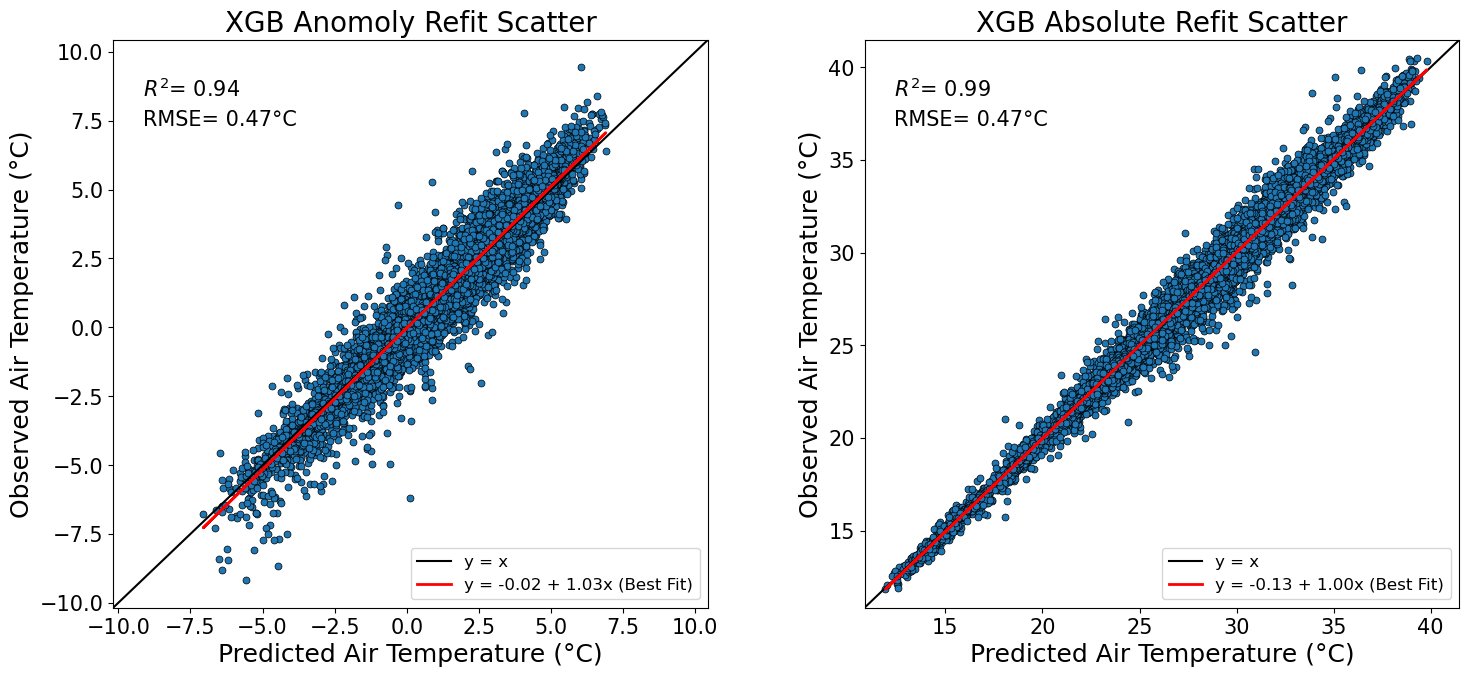

In [56]:
model_name = 'AT XGB'

y_pred_temp_anom = day_xgb_model.predict(X_day_norm)
y_pred_overall_temp = y_pred_temp_anom + data_sol_rad['temperature_2m'].values

y_day_overall_temp = y_day + data_sol_rad['temperature_2m'].values

######################################################
###### Performance Metrics for the temp anoms ########
######################################################
#rmse
anom_rmse = np.sqrt(mean_squared_error(y_day, y_pred_temp_anom))
#r-square~
anom_r2 = r2_score(y_day, y_pred_temp_anom)
#mae
anom_mae = mean_absolute_error(y_day, y_pred_temp_anom)
print('Training Metrics--', 'RMSE:', anom_rmse, 'R-square:', anom_r2, 'MAE:', anom_mae)

######################################################
###### Performance Metrics for the overall temps #####
######################################################
#rmse
temp_rmse = np.sqrt(mean_squared_error(y_day_overall_temp, y_pred_overall_temp))
#r-square
temp_r2 = r2_score(y_day_overall_temp, y_pred_overall_temp)
#mae
temp_mae = mean_absolute_error(y_day_overall_temp, y_pred_overall_temp)
print('Test Metrics--', 'RMSE:', temp_rmse, 'R-square:', temp_r2, 'MAE:', temp_mae)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
if Y_name == 'Relative_Humidity':
    units = '%'
    xlab = 'Predicted Relative Humidity (%)'
    ylab = 'Observed Relative Humidity (%)'
else:
    units =  '\u00b0C'
    xlab = 'Predicted Air Temperature (\u00b0C)'
    ylab = 'Observed Air Temperature (\u00b0C)'

# set the plot titles
#train_title = '{} Training Obvs vs Preds ({})'.format(model_name, day_night_all_flag)
#test_title = '{} Test Obvs vs Preds ({})'.format(model_name,day_night_all_flag)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
##################### Anaomoly prediction #########################
axes[0].scatter( y_pred_temp_anom, y_day,   s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = 'XGB Anomoly Refit Scatter', 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_day), min(y_pred_temp_anom),min(y_day), min(y_pred_temp_anom)) - 1
axesmax = max(max(y_day), max(y_pred_temp_anom), max(y_day), max(y_pred_temp_anom)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_day, sm.add_constant(y_pred_temp_anom)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_pred_temp_anom))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_pred_temp_anom, a*y_pred_temp_anom+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(anom_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}{}'.format(round(anom_rmse, 2), units), fontsize=15, transform=axes[0].transAxes)

axes[0].legend(loc = 4)

##################### Overall ###########################
axes[1].scatter(y_pred_overall_temp,  y_day_overall_temp,  s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = 'XGB Absolute Refit Scatter', 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_day_overall_temp), min(y_pred_overall_temp),min(y_day_overall_temp), min(y_pred_overall_temp)) - 1
axesmax = max(max(y_day_overall_temp), max(y_pred_overall_temp), max(y_day_overall_temp), max(y_pred_overall_temp)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
# x = y line
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_day_overall_temp, sm.add_constant(y_pred_overall_temp)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]

sm_pred = sm_model.get_prediction(sm.add_constant(y_pred_overall_temp))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[1].plot(y_pred_overall_temp, a*y_pred_overall_temp+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#text labels
axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(temp_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}{}'.format(round(temp_rmse, 2), units), fontsize=15, transform=axes[1].transAxes)

axes[1].legend(loc = 4)





#save the plot
#filepath = 'XGB_AT_predicted_vs_observed_trained_all_data.png'
#plt.savefig(filepath, dpi=300)

In [57]:
## FITTING THE MODELS FOR RH ##


### --- Define Model specs -----
# define Y and X
Y_name = "rh_anom"

# static variables first, then dynamic
X_names_day =[ 'NDBI_2024SummerMosaic', 'ESA_50',  
               'NDMI', 'Tree_DSM_SVF','Albedo_2024SummerMosaic',
         'zenith_angle', 'surface_net_thermal_radiation_hourly','surface_solar_radiation_downwards_hourly',
        'surface_thermal_radiation_downwards_hourly',  'surface_solar_radiation_downwards_accumulation',
        'u_component_of_wind_10m',  'v_component_of_wind_10m', 'windspeed_10m', 
        'relative_humidity_2m', 'temperature_2m', 'total_precipitation_hourly',
           ]

X_names_night =['NDBI_2024SummerMosaic', 'ESA_50',  
         'nearest_motorway_thru_primary_dist','NDMI', 'Tree_DSM_SVF',
         'zenith_angle', 'surface_net_thermal_radiation_hourly',
        'surface_thermal_radiation_downwards_hourly',  'surface_solar_radiation_downwards_accumulation',
        'u_component_of_wind_10m',  'v_component_of_wind_10m', 'windspeed_10m', 
        'relative_humidity_2m', 'temperature_2m', 'total_precipitation_hourly',
           ]


# modelling for no incoming sol rad (nighttime)
data_no_sol_rad = data[data['surface_solar_radiation_downwards_hourly'] < 1].copy().reset_index(drop = True)
y_night = data_no_sol_rad[Y_name].copy()
X_night = data_no_sol_rad[X_names_night].copy()

#create normalised datasets and save the scalers
scaler = StandardScaler()
X_night_norm = pd.DataFrame(scaler.fit_transform(X_night.values), columns = X_night.columns) #fit and transform
if landcover_shade_bias_test =='None':
    filename =  'rh_night_scaler.sav'
else: filename = f'rh_night_scaler_{landcover_shade_bias_test}.sav'
joblib.dump(scaler, filename, compress = 0)

# modelling for incoming sol rad (daytime)
data_sol_rad = data[data['surface_solar_radiation_downwards_hourly'] > 1].copy().reset_index(drop = True)
y_day = data_sol_rad[Y_name].copy()
X_day = data_sol_rad[X_names_day].copy()

#create normalised datasets
scaler = StandardScaler()
X_day_norm = pd.DataFrame(scaler.fit_transform(X_day.values), columns = X_day.columns) #fit and transform
if landcover_shade_bias_test =='None':
    filename =  'rh_day_scaler.sav'
else: filename = f'rh_day_scaler_{landcover_shade_bias_test}.sav'
joblib.dump(scaler, filename, compress = 0)

# fit and save the models 

# Daytime Model
day_xgb_model_rh = XGBRegressor(objective='reg:squarederror', random_state=42,
                             n_estimators =883,max_depth = 8, learning_rate = 0.059,
                             subsample = 0.6,colsample_bytree = 0.61, min_child_weight =17,
                             gamma =  0.001,reg_alpha =0.0001 ,reg_lambda=80) 

day_xgb_model_rh.fit(X_day_norm, y_day)

#save the file using joblib
if landcover_shade_bias_test =='None':
    filename = 'xgb_model_daytime_rh.sav'
else: filename = f'xgb_model_daytime_rh_{landcover_shade_bias_test}.sav'
joblib.dump(day_xgb_model_rh, filename)

# Nighttime Model
night_xgb_model_rh = XGBRegressor(objective='reg:squarederror', random_state=42,
                             n_estimators =700,max_depth = 7, learning_rate = 0.2,
                             subsample = 0.9,colsample_bytree = 0.4, min_child_weight =26,
                             gamma =  0.014,reg_alpha =0.002 ,reg_lambda=57) 

night_xgb_model_rh.fit(X_night_norm, y_night)

#save the file using joblib
if landcover_shade_bias_test =='None':
    filename = 'xgb_model_nighttime_rh.sav'
else: filename = f'xgb_model_nighttime_rh_{landcover_shade_bias_test}.sav'
joblib.dump(night_xgb_model_rh, filename)

['xgb_model_nighttime_rh.sav']

Training Metrics-- RMSE: 2.310791621982471 R-square: 0.9394667716147584 MAE: 1.5804316095144764
Test Metrics-- RMSE: 2.308495737770141 R-square: 0.9854096741160244 MAE: 1.5725746317114686


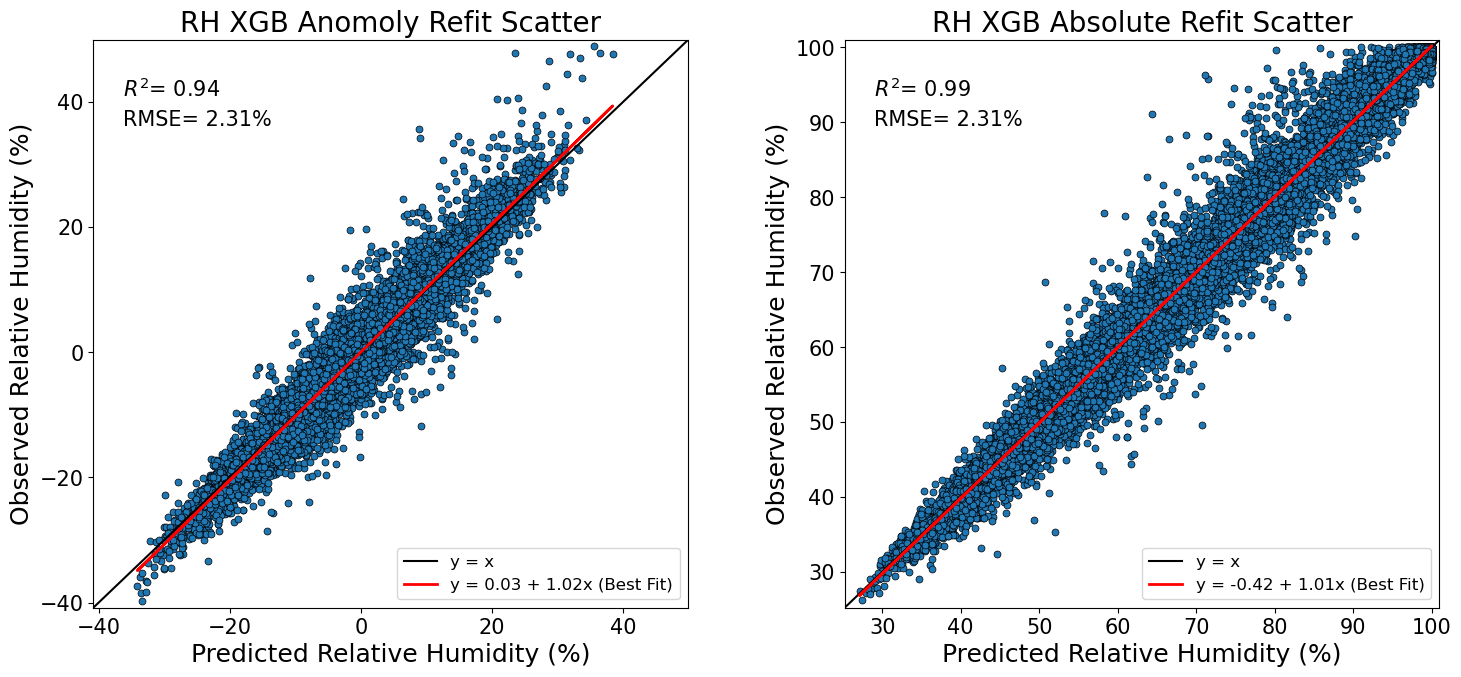

In [58]:
model_name = 'RH XGB'

y_pred_temp_anom = day_xgb_model_rh.predict(X_day_norm)
y_pred_overall_temp = y_pred_temp_anom + data_sol_rad['relative_humidity_2m'].values
y_pred_overall_temp = np.clip(y_pred_overall_temp, a_min=0, a_max=100) # bound to valid range
y_day_overall_temp = y_day + data_sol_rad['relative_humidity_2m'].values

######################################################
###### Performance Metrics for the temp anoms ########
######################################################
#rmse
anom_rmse = np.sqrt(mean_squared_error(y_day, y_pred_temp_anom))
#r-square~
anom_r2 = r2_score(y_day, y_pred_temp_anom)
#mae
anom_mae = mean_absolute_error(y_day, y_pred_temp_anom)
print('Training Metrics--', 'RMSE:', anom_rmse, 'R-square:', anom_r2, 'MAE:', anom_mae)

######################################################
###### Performance Metrics for the overall temps #####
######################################################
#rmse
temp_rmse = np.sqrt(mean_squared_error(y_day_overall_temp, y_pred_overall_temp))
#r-square
temp_r2 = r2_score(y_day_overall_temp, y_pred_overall_temp)
#mae
temp_mae = mean_absolute_error(y_day_overall_temp, y_pred_overall_temp)
print('Test Metrics--', 'RMSE:', temp_rmse, 'R-square:', temp_r2, 'MAE:', temp_mae)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
units = '%'
xlab = 'Predicted Relative Humidity (%)'
ylab = 'Observed Relative Humidity (%)'

# set the plot titles
#train_title = '{} Training Obvs vs Preds ({})'.format(model_name, day_night_all_flag)
#test_title = '{} Test Obvs vs Preds ({})'.format(model_name,day_night_all_flag)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
##################### Anaomoly prediction #########################
axes[0].scatter( y_pred_temp_anom, y_day,   s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = 'RH XGB Anomoly Refit Scatter', 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_day), min(y_pred_temp_anom),min(y_day), min(y_pred_temp_anom)) - 1
axesmax = max(max(y_day), max(y_pred_temp_anom), max(y_day), max(y_pred_temp_anom)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_day, sm.add_constant(y_pred_temp_anom)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_pred_temp_anom))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_pred_temp_anom, a*y_pred_temp_anom+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(anom_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}{}'.format(round(anom_rmse, 2), units), fontsize=15, transform=axes[0].transAxes)

axes[0].legend(loc = 4)

##################### Overall ###########################
axes[1].scatter(y_pred_overall_temp,  y_day_overall_temp,  s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = 'RH XGB Absolute Refit Scatter', 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_day_overall_temp), min(y_pred_overall_temp),min(y_day_overall_temp), min(y_pred_overall_temp)) - 1
axesmax = max(max(y_day_overall_temp), max(y_pred_overall_temp), max(y_day_overall_temp), max(y_pred_overall_temp)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
# x = y line
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_day_overall_temp, sm.add_constant(y_pred_overall_temp)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]

sm_pred = sm_model.get_prediction(sm.add_constant(y_pred_overall_temp))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[1].plot(y_pred_overall_temp, a*y_pred_overall_temp+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#text labels
axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(temp_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}{}'.format(round(temp_rmse, 2), units), fontsize=15, transform=axes[1].transAxes)

axes[1].legend(loc = 4)


#save the plot
#filepath = 'XGB_RH_predicted_vs_observed_trained_all_data.png'
#plt.savefig(filepath, dpi=300)